# 第三周：多维期权 Alpha 因子池构建

**完成日期**：2026.10.29 - 2026.11.04

**研究区间**：2018.01.01 - 2025.12.31

---

## 一、本周目标

1. 基于第二周已完成的 BS-IV 反推、RV/VRP 数据集，构建四类期权 Alpha 因子：
   - VRP 波动率溢价因子（核心信号）；
   - 波动率偏斜 Skew 因子（尾部恐慌风险信号）；
   - PCR 多空情绪因子（看涨看跌成交结构）；
   - 波动率期限结构因子（近远月波动预期差）。
2. 统一因子口径：日频、按交易日对齐、严格使用历史信息，避免未来函数。
3. 对四类因子进行描述性统计、缺失值/异常值检查、相关性初检。
4. 输出标准化因子池，为第四周 Rank-IC、IR、五分位分层回测与因子正交化检验做准备。
5. 明确剔除 LSMC 定价残差因子：该因子计算成本高，且对欧式期权边际信息有限，不纳入本周因子池。

---

## 二、本周详细步骤

### 步骤 1：核心 VRP 因子复核与信号化
- 读取第二周 `vrp_factor.parquet`，复核 `ATM_IV / RV_22d / VRP / VRP_MA5 / VRP_Zscore` 字段完整性。
- 计算 VRP_MA5 的 252 日滚动历史分位，刻画当前溢价水平。
- 按大纲阈值生成信号状态：
  - `VRP_Zscore > 1.5`：`HIGH_SELL`，期权被高估，满仓备兑/卖 Call 收租；
  - `-1.5 <= VRP_Zscore <= 1.5`：`NEUTRAL`，降低卖权敞口、适度控险；
  - `VRP_Zscore < -1.5`：`LOW_PROTECT`，停止卖权，极端恐慌可买入 Put 保护。
- 增加 `circuit_breaker` 熔断标记与建议卖权敞口字段，为第五周策略做信号准备。
- 合并现货未来收益标签，仅用于第三/四周因子有效性统计，不参与信号生成。
- 输出 VRP 核心信号表、分组统计表、VRP Z-score 信号图。

### 步骤 2：波动率偏斜 Skew 因子构建
- 基于近月期权链，提取虚值 Put 与虚值 Call 的 IV。
- 构建 Skew 因子，例如：
  - `Skew_25D = IV_Put_25D - IV_Call_25D`；
  - 或 `Skew_OTM = IV_Put_OTM - IV_ATM`。
- 按日聚合，检查缺失值与极端值，输出 `week3_skew_factor.parquet`。
- 绘制 Skew 时序图，观察其在恐慌区间与尾部风险事件中的表现。

### 步骤 3：PCR 多空情绪因子构建
- 基于全期权链成交量与持仓量，分别构建：
  - `PCR_Volume = Put 成交量 / Call 成交量`；
  - `PCR_OI = Put 持仓量 / Call 持仓量`。
- 可按近月合约与全合约两种口径分别计算，最终保留稳定性更强的口径。
- 输出 `week3_pcr_factor.parquet`，并绘制 PCR 与标的走势对照图。

### 步骤 4：波动率期限结构因子构建
- 提取近月与远月 ATM IV。
- 构建期限结构因子：
  - `TermSpread = IV_近月 - IV_远月`；
  - 或 `TermRatio = IV_近月 / IV_远月`。
- 按日聚合，输出 `week3_term_structure_factor.parquet`。
- 分析近远月波动预期差在事件冲击、恐慌期与平稳期的变化。

### 步骤 5：因子池合并、描述统计与有效性初检
- 将 VRP、Skew、PCR、Term Structure 四类因子按 `trade_date` 合并。
- 统一缺失值处理规则：因子缺失日不强行填充，回测时按可用因子日处理。
- 输出因子池 `week3_alpha_factor_pool.parquet`。
- 计算因子描述性统计、相关性矩阵、初步 Rank-IC。
- 形成 `week3_factor_summary.csv`、`week3_factor_corr.png`、`week3_factor_ic.csv`。
- 编写 `docs/week3_factor_dictionary.md`，说明每个因子的经济学含义、计算口径、方向解释与使用约束。

---

## 三、输出目录

| 文件 | 路径 | 说明 |
|------|------|------|
| VRP 核心信号表 | `data/derived/week3_vrp_signal.parquet` | 含 VRP、Z-score、滚动分位、信号状态、建议卖权敞口 |
| VRP 分组统计表 | `data/derived/week3_vrp_signal_summary.csv` | 按信号状态统计样本数、VRP 均值、未来收益均值 |
| Skew 因子 | `data/derived/week3_skew_factor.parquet` | 波动率偏斜因子 |
| PCR 因子 | `data/derived/week3_pcr_factor.parquet` | 成交量/持仓量 PCR |
| 期限结构因子 | `data/derived/week3_term_structure_factor.parquet` | 近远月 ATM IV 差/比 |
| 四因子池 | `data/derived/week3_alpha_factor_pool.parquet` | 日频多维 Alpha 因子池 |
| VRP 信号图 | `report/week3/week3_vrp_signal.png` | VRP Z-score 与信号状态 |
| 因子相关性图 | `report/week3/week3_factor_corr.png` | 四因子相关性矩阵 |
| 因子 IC 初检 | `data/derived/week3_factor_ic.csv` | Rank-IC / IR 初检结果 |
| 因子说明文档 | `docs/week3_factor_dictionary.md` | 因子口径与使用说明 |

---

## 四、本周注意事项

1. **严格防未来函数**：Z-score、滚动分位、信号状态均只使用当日及历史窗口；未来收益仅用于统计检验。
2. **VRP 不重复定价**：第二周已完成 BS-IV 反推与 RV/VRP 构建，本周步骤 1 只做信号工程与统计复核。
3. **阈值仅作初版**：`±1.5σ` 来自项目大纲，第五周需做参数敏感性测试。
4. **因子池聚焦四类**：不纳入 LSMC 定价残差因子，避免计算成本高且边际信息有限。

### 步骤 1：核心 VRP 因子复核与信号化

**目标**：基于第二周产出的 `vrp_factor.parquet`，完成 VRP 核心信号的工程化处理，生成可直接供第三/四周统计检验与第五周策略调用的日频信号表。

**输入文件**：
- `data/derived/vrp_factor.parquet`：第二周产出的 VRP 因子数据，含 `trade_date / ATM_IV / RV_22d / VRP / VRP_MA5 / VRP_Zscore`。
- `data/raw/50etf_spot.csv`：50ETF 现货日线数据，用于计算未来收益标签。

**输出文件**：
- `data/derived/week3_vrp_signal.parquet`：VRP 核心信号表。
- `data/derived/week3_vrp_signal_summary.csv`：按信号状态分组统计表。
- `report/week3/week3_vrp_signal.png`：VRP Z-score 与信号状态可视化。

**内容**：
- 复核 VRP 因子字段完整性与交易日排序。
- 计算 `VRP_MA5` 的 252 日滚动历史分位 `VRP_MA5_rank_252`。
- 按大纲阈值生成 `signal_state`：
  - `VRP_Zscore > 1.5` → `HIGH_SELL`；
  - `-1.5 <= VRP_Zscore <= 1.5` → `NEUTRAL`；
  - `VRP_Zscore < -1.5` → `LOW_PROTECT`。
- 增加 `is_extreme_high`、`is_extreme_low`、`circuit_breaker`、`suggested_sell_call_exposure` 字段。
- 合并现货未来 1/5/10/20 日收益，仅用于因子有效性统计，不参与信号生成。
- 输出分组统计表与信号图。

**注意**：
- `VRP_Zscore` 已由第二周按 60 日滚动窗口计算，本周不重新估计，避免口径漂移。
- 滚动分位使用 252 日窗口、最少 60 个观测，且只使用历史数据。
- 未来收益列 `fwd_ret_*` 仅用于统计检验；第五周回测信号必须使用 `shift(1)` 后的信号。
- `suggested_sell_call_exposure` 为初版建议敞口：`HIGH_SELL=1.0`、`NEUTRAL=0.5`、`LOW_PROTECT=0.0`，后续第五周可调。

  第3周 - 步骤1: 核心 VRP 因子复核与信号化

【1.1】读取 VRP 因子与现货数据 ...
  VRP 因子样本数: 1761
  时间范围: 20180702 - 20251231
trade_date   ATM_IV   RV_22d      VRP  VRP_MA5  VRP_Zscore
  20180702 0.263879 0.225794 0.038085 0.037277   -0.031138
  20180703 0.260920 0.213367 0.047553 0.039178    0.394065
  20180704 0.273145 0.213716 0.059430 0.042702    0.935230
  20180705 0.278217 0.202280 0.075936 0.047327    1.732679
  20180706 0.260679 0.210349 0.050330 0.054267    0.587765

【1.2】计算 VRP_MA5 的 252 日滚动历史分位 ...

【1.3】生成 VRP 信号状态 ...
signal_state
NEUTRAL        1398
LOW_PROTECT     263
HIGH_SELL       100

信号状态示例：
trade_date      VRP  VRP_MA5  VRP_Zscore  VRP_MA5_rank_252 signal_state  suggested_sell_call_exposure
  20251209 0.162269 0.168118    1.717908          0.980159    HIGH_SELL                           1.0
  20251210 0.186856 0.162110    2.015659          0.976190    HIGH_SELL                           1.0
  20251211 0.208420 0.162428    2.227668          0.976190    HIGH_SELL                           1.0

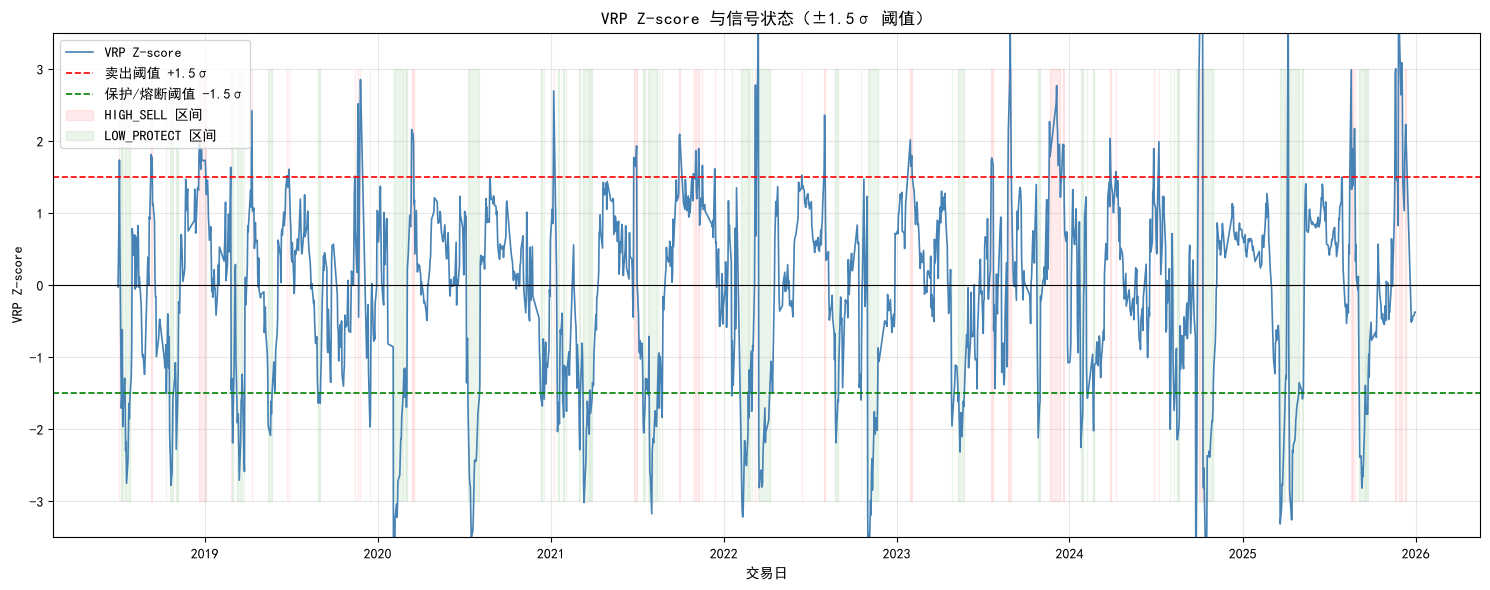

  💾 已保存: D:\50etf_option_project\report\week3\week3_vrp_signal.png

  第3周 - 步骤1 完成 ✅


In [3]:
# ==========================================================
# 第3周 - 步骤1: 核心 VRP 因子复核与信号化
# ==========================================================
import sys, os
PROJECT_ROOT = r"D:\50etf_option_project"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from etf_src.config import DATA_RAW, DATA_DERIVED

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

REPORT_WEEK3_DIR = os.path.join(PROJECT_ROOT, "report", "week3")
os.makedirs(REPORT_WEEK3_DIR, exist_ok=True)

print("=" * 70)
print("  第3周 - 步骤1: 核心 VRP 因子复核与信号化")
print("=" * 70)

# ----------------------------------------------------------
# 1.1 读取第二周 VRP 因子与现货数据
# ----------------------------------------------------------
print("\n【1.1】读取 VRP 因子与现货数据 ...")

vrp = pd.read_parquet(os.path.join(DATA_DERIVED, "vrp_factor.parquet"))
vrp['trade_date'] = vrp['trade_date'].astype(str)
vrp = vrp.sort_values('trade_date').reset_index(drop=True)

required_cols = ['trade_date', 'ATM_IV', 'RV_22d', 'VRP', 'VRP_MA5', 'VRP_Zscore']
missing_cols = [c for c in required_cols if c not in vrp.columns]
if missing_cols:
    raise ValueError(f"vrp_factor.parquet 缺少字段: {missing_cols}")

spot = pd.read_csv(os.path.join(DATA_RAW, "50etf_spot.csv"))
spot['trade_date'] = spot['trade_date'].astype(str)
spot = spot.sort_values('trade_date').reset_index(drop=True)

# 未来收益仅用于因子统计检验，不参与信号生成
for n in [1, 5, 10, 20]:
    spot[f'fwd_ret_{n}d'] = spot['close'].shift(-n) / spot['close'] - 1.0

fwd_cols = [f'fwd_ret_{n}d' for n in [1, 5, 10, 20]]
spot_fwd = spot[['trade_date'] + fwd_cols].copy()

df = pd.merge(vrp, spot_fwd, on='trade_date', how='left')
df = df.sort_values('trade_date').reset_index(drop=True)

print(f"  VRP 因子样本数: {len(df)}")
print(f"  时间范围: {df['trade_date'].min()} - {df['trade_date'].max()}")
print(df[['trade_date', 'ATM_IV', 'RV_22d', 'VRP', 'VRP_MA5', 'VRP_Zscore']].head().to_string(index=False))

# ----------------------------------------------------------
# 1.2 计算 VRP_MA5 的 252 日滚动历史分位
# ----------------------------------------------------------
print("\n【1.2】计算 VRP_MA5 的 252 日滚动历史分位 ...")

def rolling_last_percentile(s, window=252, min_periods=60):
    """
    对每个时点，计算当前值在过去 window 个观测中的百分位排名。
    只使用历史窗口，避免未来函数。
    """
    return s.rolling(window=window, min_periods=min_periods).apply(
        lambda x: pd.Series(x).rank(pct=True).iloc[-1],
        raw=False
    )

df['VRP_MA5_rank_252'] = rolling_last_percentile(df['VRP_MA5'], window=252, min_periods=60)

# ----------------------------------------------------------
# 1.3 按大纲阈值生成信号状态与建议卖权敞口
# ----------------------------------------------------------
print("\n【1.3】生成 VRP 信号状态 ...")

z = df['VRP_Zscore']

df['is_extreme_high'] = (z > 1.5).astype(int)
df['is_extreme_low'] = (z < -1.5).astype(int)
df['circuit_breaker'] = (z < -1.5).astype(int)

conditions = [
    z > 1.5,
    (z >= -1.5) & (z <= 1.5),
    z < -1.5
]
choices = ['HIGH_SELL', 'NEUTRAL', 'LOW_PROTECT']
df['signal_state'] = np.select(conditions, choices, default='NEUTRAL')

# 初版建议卖权敞口：HIGH_SELL=1.0，NEUTRAL=0.5，LOW_PROTECT=0.0
# 第五周回测中可做参数敏感性测试
exposure_conditions = [
    df['signal_state'] == 'HIGH_SELL',
    df['signal_state'] == 'NEUTRAL',
    df['signal_state'] == 'LOW_PROTECT'
]
df['suggested_sell_call_exposure'] = np.select(
    exposure_conditions,
    [1.0, 0.5, 0.0],
    default=np.nan
)

print(df['signal_state'].value_counts(dropna=False).to_string())
print("\n信号状态示例：")
print(df[['trade_date', 'VRP', 'VRP_MA5', 'VRP_Zscore', 'VRP_MA5_rank_252',
          'signal_state', 'suggested_sell_call_exposure']].tail(10).to_string(index=False))

# ----------------------------------------------------------
# 1.4 分组统计：按信号状态统计 VRP 与未来收益
# ----------------------------------------------------------
print("\n【1.4】按信号状态分组统计 ...")

summary = (
    df.groupby('signal_state', dropna=False)
      .agg(
          sample_count=('trade_date', 'count'),
          vrp_mean=('VRP', 'mean'),
          vrp_ma5_mean=('VRP_MA5', 'mean'),
          zscore_mean=('VRP_Zscore', 'mean'),
          rank252_mean=('VRP_MA5_rank_252', 'mean'),
          fwd_ret_1d_mean=('fwd_ret_1d', 'mean'),
          fwd_ret_5d_mean=('fwd_ret_5d', 'mean'),
          fwd_ret_10d_mean=('fwd_ret_10d', 'mean'),
          fwd_ret_20d_mean=('fwd_ret_20d', 'mean')
      )
      .reset_index()
)

# 按业务顺序排序
state_order = {'HIGH_SELL': 0, 'NEUTRAL': 1, 'LOW_PROTECT': 2}
summary['_order'] = summary['signal_state'].map(state_order).fillna(99)
summary = summary.sort_values('_order').drop(columns='_order').reset_index(drop=True)

print(summary.to_string(index=False))

summary_file = os.path.join(DATA_DERIVED, "week3_vrp_signal_summary.csv")
summary.to_csv(summary_file, index=False, encoding='utf-8-sig')
print(f"\n  💾 已保存: {summary_file}")

# ----------------------------------------------------------
# 1.5 保存 VRP 核心信号表
# ----------------------------------------------------------
out_cols = [
    'trade_date', 'ATM_IV', 'RV_22d', 'VRP', 'VRP_MA5', 'VRP_Zscore',
    'VRP_MA5_rank_252', 'is_extreme_high', 'is_extreme_low',
    'circuit_breaker', 'signal_state', 'suggested_sell_call_exposure',
    'fwd_ret_1d', 'fwd_ret_5d', 'fwd_ret_10d', 'fwd_ret_20d'
]
df_out = df[out_cols].copy()

out_file = os.path.join(DATA_DERIVED, "week3_vrp_signal.parquet")
df_out.to_parquet(out_file, index=False)
print(f"  💾 已保存: {out_file} (共 {len(df_out)} 条)")

# ----------------------------------------------------------
# 1.6 可视化：VRP Z-score 与信号状态
# ----------------------------------------------------------
print("\n【1.6】绘制 VRP 信号图 ...")

plot_df = df_out.copy()
plot_df['trade_date_dt'] = pd.to_datetime(plot_df['trade_date'], format='%Y%m%d')

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(plot_df['trade_date_dt'], plot_df['VRP_Zscore'],
        color='steelblue', linewidth=1.2, label='VRP Z-score')

ax.axhline(1.5, color='red', linestyle='--', linewidth=1.2, label='卖出阈值 +1.5σ')
ax.axhline(-1.5, color='green', linestyle='--', linewidth=1.2, label='保护/熔断阈值 -1.5σ')
ax.axhline(0, color='black', linewidth=0.8)

# 高溢价区间背景
high_mask = plot_df['VRP_Zscore'] > 1.5
low_mask = plot_df['VRP_Zscore'] < -1.5
ax.fill_between(plot_df['trade_date_dt'], -3, 3, where=high_mask,
                color='red', alpha=0.08, label='HIGH_SELL 区间')
ax.fill_between(plot_df['trade_date_dt'], -3, 3, where=low_mask,
                color='green', alpha=0.08, label='LOW_PROTECT 区间')

ax.set_title('VRP Z-score 与信号状态（±1.5σ 阈值）')
ax.set_ylabel('VRP Z-score')
ax.set_xlabel('交易日')
ax.set_ylim(-3.5, 3.5)
ax.legend(loc='upper left')
ax.grid(alpha=0.3)

plt.tight_layout()
plot_file = os.path.join(REPORT_WEEK3_DIR, "week3_vrp_signal.png")
plt.savefig(plot_file, dpi=120)
plt.show()
print(f"  💾 已保存: {plot_file}")

print("\n" + "=" * 70)
print("  第3周 - 步骤1 完成 ✅")
print("=" * 70)

### 步骤 2, 3 & 4：波动率偏斜、PCR 与期限结构因子构建

**目标**：从尾部风险（Skew）、情绪面（PCR）、期限预期（Term Structure）三个维度，构建高质量期权 Alpha 因子。本步骤已针对期权市场的“低流动性”和“报价失真”问题进行了加固优化，并输出三张独立因子时序图以便直观检查。

**输入文件**：
- `data/derived/option_daily_with_iv.parquet`：全量期权数据（含 IV, T, moneyness, call_put, vol 等字段）。

**输出文件**：
- `data/derived/week3_skew_factor.parquet`
- `data/derived/week3_pcr_factor.parquet`
- `data/derived/week3_term_structure_factor.parquet`
- `report/week3/week3_skew_timeseries.png`：Skew 因子时序图。
- `report/week3/week3_pcr_timeseries.png`：PCR 因子时序图。
- `report/week3/week3_term_timeseries.png`：期限结构时序图。

**核心优化点（防坑指南）**：
1. **全局流动性清洗**：期权挂单极易出现“有价无市”的虚假报价，计算前严格剔除当日成交量 `< 100` 张的合约，只保留活跃合约。
2. **防虚假平稳（Skew & Term）**：严禁无限制的 `ffill`。对于缺失值，最多只允许向前填充 2 天（涵盖周末/短假），若长假或无成交，保持 `NaN`。此举防止连续多日使用同一旧数据计算 IC 导致的高估。
3. **PCR 情绪纯度**：计算 PCR 时，剔除极端虚值合约（保留 moneyness 在 0.8 - 1.2 之间），避免散户“买彩票”的微量成交干扰真实的机构多空博弈。
4. **期限结构平滑**：远月合约通常流动性不佳，容易产生单日 IV 毛刺。对计算出的 `TermSpread` 采用 3 日滚动均值平滑。

**内容**：
- **Skew 因子**：提取近月（T<0.15）虚值 Put（0.85-0.95）与虚值 Call（1.05-1.15）的 IV 均值，相减得到 `Skew_OTM`。
- **PCR 因子**：按日计算 Put 与 Call 的成交量比值，得到 `PCR_Volume`。
- **期限结构**：计算近月（T<0.15）与远月（0.15<=T<=0.5）平值 IV（0.98-1.02）的差值，平滑后得到 `TermSpread_Smooth`。

  第3周 - 步骤2, 3 & 4: 因子构建（加固优化版）

【2.0】基础数据加载与流动性清洗 ...

【2.1】构建 Skew 因子 ...
  💾 已保存: D:\50etf_option_project\data\derived\week3_skew_factor.parquet (有效样本: 1777 条)

【3.1】构建 PCR 因子 ...
  💾 已保存: D:\50etf_option_project\data\derived\week3_pcr_factor.parquet (有效样本: 1880 条)

【4.1】构建期限结构因子 ...
  💾 已保存: D:\50etf_option_project\data\derived\week3_term_structure_factor.parquet (有效样本: 1880 条)

【5.1】分别绘制三张因子图 ...


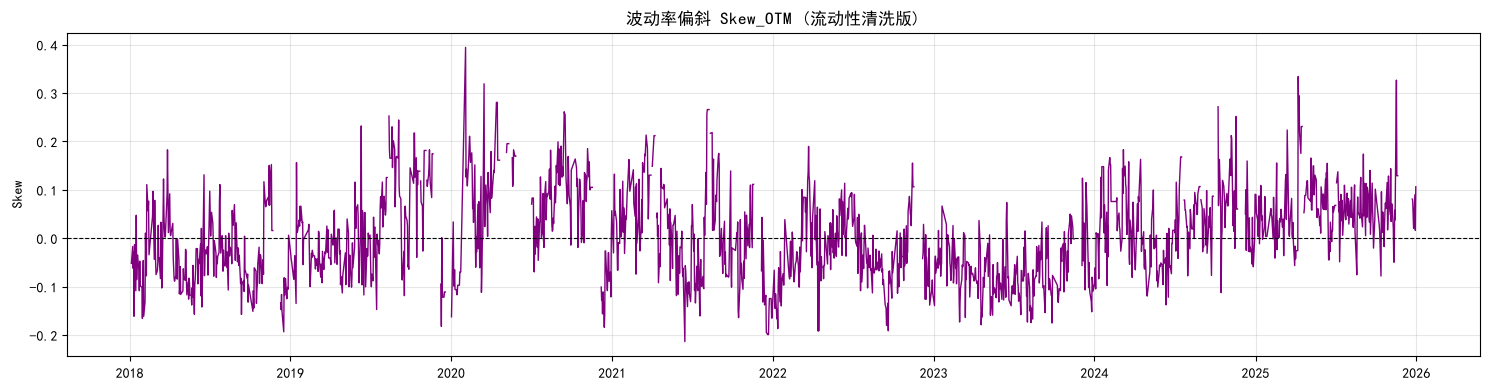

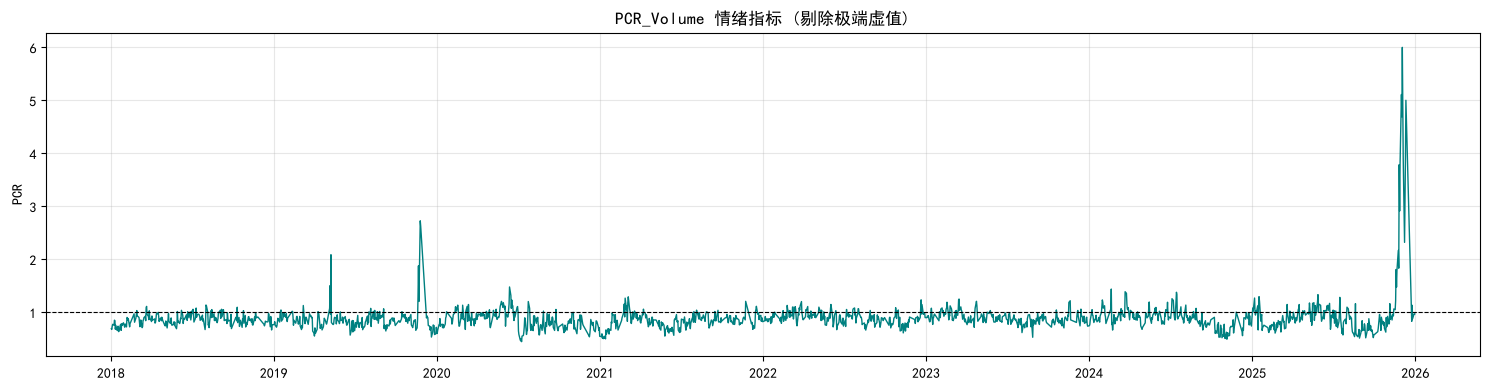

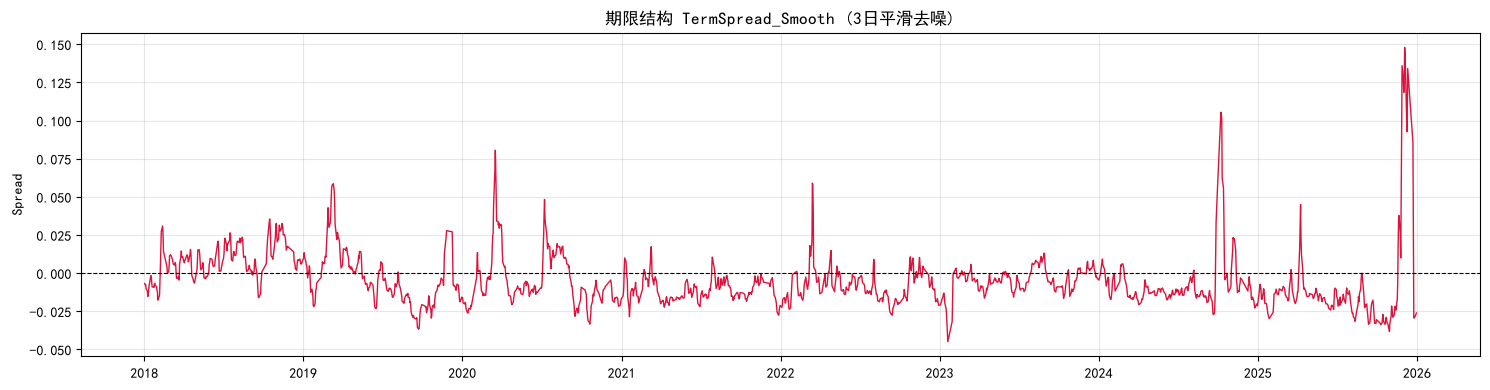


  ✅ 三张因子图已分别保存至: D:\50etf_option_project\report\week3

  第3周 - 步骤2, 3 & 4 完成 ✅ 因子已去噪加固


In [6]:
# ==========================================================
# 第3周 - 步骤2, 3 & 4: 因子构建（流动性过滤与加固优化版）
# ==========================================================
import sys, os
PROJECT_ROOT = r"D:\50etf_option_project"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from etf_src.config import DATA_DERIVED

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
REPORT_WEEK3_DIR = os.path.join(PROJECT_ROOT, "report", "week3")
os.makedirs(REPORT_WEEK3_DIR, exist_ok=True)

print("=" * 70)
print("  第3周 - 步骤2, 3 & 4: 因子构建（加固优化版）")
print("=" * 70)

# ----------------------------------------------------------
# 2.0 基础数据加载与流动性全局过滤
# ----------------------------------------------------------
print("\n【2.0】基础数据加载与流动性清洗 ...")

df_iv = pd.read_parquet(os.path.join(DATA_DERIVED, "option_daily_with_iv.parquet"))
df_iv['trade_date'] = df_iv['trade_date'].astype(str)

# 兼容列名 (你的数据中可能是 vol 或 volume)
vol_col = 'vol' if 'vol' in df_iv.columns else 'volume'

# 核心优化 1：剔除 IV 失真报价 + 剔除成交量过低（<100张）的无效合约
df_clean = df_iv[
    (df_iv['IV'] > 0.01) & (df_iv['IV'] < 3.0) & 
    (df_iv[vol_col] >= 100)
].copy()

# ----------------------------------------------------------
# 2.1 波动率偏斜 Skew 因子构建
# ----------------------------------------------------------
print("\n【2.1】构建 Skew 因子 ...")

# 提取近月合约
df_near = df_clean[df_clean['T'] < 0.15].copy()

# 划分虚值区间并求每日 IV 均值
df_put_otm = df_near[(df_near['moneyness'] >= 0.85) & (df_near['moneyness'] <= 0.95) & (df_near['call_put'] == 'P')]
df_call_otm = df_near[(df_near['moneyness'] >= 1.05) & (df_near['moneyness'] <= 1.15) & (df_near['call_put'] == 'C')]

skew_df = pd.DataFrame({
    'IV_Put_OTM': df_put_otm.groupby('trade_date')['IV'].mean(),
    'IV_Call_OTM': df_call_otm.groupby('trade_date')['IV'].mean()
}).reset_index()

skew_df['Skew_OTM'] = skew_df['IV_Put_OTM'] - skew_df['IV_Call_OTM']

# 核心优化 2：限制填充最多 2 天（防长假/断档期的虚假平稳）
skew_df = skew_df.sort_values('trade_date').reset_index(drop=True)
skew_df[['IV_Put_OTM', 'IV_Call_OTM', 'Skew_OTM']] = skew_df[['IV_Put_OTM', 'IV_Call_OTM', 'Skew_OTM']].ffill(limit=2)

skew_file = os.path.join(DATA_DERIVED, "week3_skew_factor.parquet")
skew_df.to_parquet(skew_file, index=False)
print(f"  💾 已保存: {skew_file} (有效样本: {skew_df['Skew_OTM'].count()} 条)")

# ----------------------------------------------------------
# 3.1 PCR 多空情绪因子构建
# ----------------------------------------------------------
print("\n【3.1】构建 PCR 因子 ...")

# 核心优化 3：剔除极端虚值合约，防“买彩票”噪音干扰
df_pcr_clean = df_clean[(df_clean['moneyness'] >= 0.8) & (df_clean['moneyness'] <= 1.2)]

pcr_daily = df_pcr_clean.groupby(['trade_date', 'call_put'])[vol_col].sum().unstack()
pcr_daily.columns = [f'vol_{c}' for c in pcr_daily.columns]

# 计算 PCR，加 1e-6 防止除 0
pcr_daily['PCR_Volume'] = pcr_daily['vol_P'] / (pcr_daily['vol_C'] + 1e-6)
pcr_df = pcr_daily.reset_index()[['trade_date', 'PCR_Volume']].sort_values('trade_date').reset_index(drop=True)

pcr_file = os.path.join(DATA_DERIVED, "week3_pcr_factor.parquet")
pcr_df.to_parquet(pcr_file, index=False)
print(f"  💾 已保存: {pcr_file} (有效样本: {pcr_df['PCR_Volume'].count()} 条)")

# ----------------------------------------------------------
# 4.1 波动率期限结构因子构建
# ----------------------------------------------------------
print("\n【4.1】构建期限结构因子 ...")

df_near_atm = df_near[(df_near['moneyness'] >= 0.98) & (df_near['moneyness'] <= 1.02)]
df_far_atm = df_clean[(df_clean['T'] >= 0.15) & (df_clean['T'] <= 0.5) & 
                      (df_clean['moneyness'] >= 0.98) & (df_clean['moneyness'] <= 1.02)]

term_df = pd.DataFrame({
    'IV_Near': df_near_atm.groupby('trade_date')['IV'].mean(),
    'IV_Far': df_far_atm.groupby('trade_date')['IV'].mean()
}).reset_index().sort_values('trade_date').reset_index(drop=True)

term_df['TermSpread'] = term_df['IV_Near'] - term_df['IV_Far']
term_df[['TermSpread']] = term_df[['TermSpread']].ffill(limit=2)

# 核心优化 4：对期限结构做 3 日平滑，过滤远月单日毛刺
term_df['TermSpread_Smooth'] = term_df['TermSpread'].rolling(window=3, min_periods=1).mean()

term_file = os.path.join(DATA_DERIVED, "week3_term_structure_factor.parquet")
term_df.to_parquet(term_file, index=False)
print(f"  💾 已保存: {term_file} (有效样本: {term_df['TermSpread_Smooth'].count()} 条)")

# ----------------------------------------------------------
# 5.1 可视化：分别输出三张因子图
# ----------------------------------------------------------
print("\n【5.1】分别绘制三张因子图 ...")

# ---------------- 图 1：Skew 因子 ----------------
plot_skew = skew_df.copy()
plot_skew['trade_date_dt'] = pd.to_datetime(plot_skew['trade_date'], format='%Y%m%d')

plt.figure(figsize=(15, 4))
plt.plot(plot_skew['trade_date_dt'], plot_skew['Skew_OTM'], color='purple', linewidth=1)
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('波动率偏斜 Skew_OTM (流动性清洗版)')
plt.ylabel('Skew')
plt.grid(alpha=0.3)
plt.tight_layout()
skew_plot_file = os.path.join(REPORT_WEEK3_DIR, "week3_skew_timeseries.png")
plt.savefig(skew_plot_file, dpi=120)
plt.show()
plt.close()

# ---------------- 图 2：PCR 因子 ----------------
plot_pcr = pcr_df.copy()
plot_pcr['trade_date_dt'] = pd.to_datetime(plot_pcr['trade_date'], format='%Y%m%d')

plt.figure(figsize=(15, 4))
plt.plot(plot_pcr['trade_date_dt'], plot_pcr['PCR_Volume'], color='teal', linewidth=1)
plt.axhline(1.0, color='black', linestyle='--', linewidth=0.8)
plt.title('PCR_Volume 情绪指标 (剔除极端虚值)')
plt.ylabel('PCR')
plt.grid(alpha=0.3)
plt.tight_layout()
pcr_plot_file = os.path.join(REPORT_WEEK3_DIR, "week3_pcr_timeseries.png")
plt.savefig(pcr_plot_file, dpi=120)
plt.show()
plt.close()

# ---------------- 图 3：期限结构因子 ----------------
plot_term = term_df.copy()
plot_term['trade_date_dt'] = pd.to_datetime(plot_term['trade_date'], format='%Y%m%d')

plt.figure(figsize=(15, 4))
plt.plot(plot_term['trade_date_dt'], plot_term['TermSpread_Smooth'], color='crimson', linewidth=1)
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('期限结构 TermSpread_Smooth (3日平滑去噪)')
plt.ylabel('Spread')
plt.grid(alpha=0.3)
plt.tight_layout()
term_plot_file = os.path.join(REPORT_WEEK3_DIR, "week3_term_timeseries.png")
plt.savefig(term_plot_file, dpi=120)
plt.show()
plt.close()

print(f"\n  ✅ 三张因子图已分别保存至: {REPORT_WEEK3_DIR}")

print("\n" + "=" * 70)
print("  第3周 - 步骤2, 3 & 4 完成 ✅ 因子已去噪加固")
print("=" * 70)

### 步骤 5：因子池合并、描述统计与有效性初检

**目标**：将四大独立因子整合为统一的日频 Alpha 因子池，并对因子进行 1%-99% 的缩尾去极值处理（防止后续 IC 检验被极端毛刺带偏）。最后计算因子与未来收益的 Rank-IC 以及因子间的 Spearman 相关性，完成有效性初检。

**输入文件**：
- `data/derived/week3_vrp_signal.parquet` (包含未来收益列)
- `data/derived/week3_skew_factor.parquet`
- `data/derived/week3_pcr_factor.parquet`
- `data/derived/week3_term_structure_factor.parquet`

**输出文件**：
- `data/derived/week3_alpha_factor_pool.parquet`：清洗去极值后的最终四因子池（第四周回测直接使用）。
- `report/week3/week3_factor_corr.png`：四因子 Spearman 相关性热力图。
- `data/derived/week3_factor_ic.csv`：Rank-IC 统计矩阵。

**内容**：
- **因子合并**：以 VRP 信号表的交易日为基准，左连接其余三个因子。
- **去极值处理**：使用 1% 和 99% 分位数对因子进行截尾缩进（Winsorize），因为 PCR 和 TermSpread 都有长尾特征。
- **因子正交初检**：计算相关性矩阵，排查因子之间是否存在信息冗余。
- **Rank-IC 检验**：计算每个因子分别与未来 1D/5D/10D/20D 收益的 Spearman 秩相关系数，验证预测方向。

In [7]:
# ==========================================================
# 第3周 - 步骤5: 因子池合并、描述统计与有效性初检
# ==========================================================
import sys, os
PROJECT_ROOT = r"D:\50etf_option_project"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from etf_src.config import DATA_DERIVED, DATA_RAW

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
REPORT_WEEK3_DIR = os.path.join(PROJECT_ROOT, "report", "week3")
os.makedirs(REPORT_WEEK3_DIR, exist_ok=True)

print("=" * 70)
print("  第3周 - 步骤5: 因子池合并、描述统计与有效性初检")
print("=" * 70)

# ----------------------------------------------------------
# 5.1 合并所有因子
# ----------------------------------------------------------
print("\n【5.1】合并多维因子池 ...")

df_vrp = pd.read_parquet(os.path.join(DATA_DERIVED, "week3_vrp_signal.parquet"))
df_skew = pd.read_parquet(os.path.join(DATA_DERIVED, "week3_skew_factor.parquet"))
df_pcr = pd.read_parquet(os.path.join(DATA_DERIVED, "week3_pcr_factor.parquet"))
df_term = pd.read_parquet(os.path.join(DATA_DERIVED, "week3_term_structure_factor.parquet"))

for df in [df_vrp, df_skew, df_pcr, df_term]:
    df['trade_date'] = df['trade_date'].astype(str)

# 以 VRP 为基准合并
df_pool = df_vrp.copy()
df_pool = pd.merge(df_pool, df_skew[['trade_date', 'Skew_OTM']], on='trade_date', how='left')
df_pool = pd.merge(df_pool, df_pcr[['trade_date', 'PCR_Volume']], on='trade_date', how='left')
df_pool = pd.merge(df_pool, df_term[['trade_date', 'TermSpread_Smooth']], on='trade_date', how='left')

# 重命名
df_pool.rename(columns={'TermSpread_Smooth': 'TermSpread'}, inplace=True)
factor_cols = ['VRP_Zscore', 'Skew_OTM', 'PCR_Volume', 'TermSpread']
ret_cols = ['fwd_ret_1d', 'fwd_ret_5d', 'fwd_ret_10d', 'fwd_ret_20d']

print(f"  合并后总样本数: {len(df_pool)}")
print("  缺失值统计：")
print(df_pool[factor_cols].isna().sum())

# ----------------------------------------------------------
# 5.2 因子去极值 (Winsorize 1% - 99%)
# ----------------------------------------------------------
print("\n【5.2】因子去极值 (Winsorize 1% - 99%) ...")

def winsorize_series(s, lower_q=0.01, upper_q=0.99):
    return s.clip(s.quantile(lower_q), s.quantile(upper_q))

# 注意：因为有些因子存在 NaN，在计算 quantile 时 pandas 会自动忽略
for col in factor_cols:
    df_pool[col] = winsorize_series(df_pool[col])

# ----------------------------------------------------------
# 5.3 因子间 Spearman 相关性矩阵
# ----------------------------------------------------------
print("\n【5.3】计算因子间相关性并绘图 ...")

corr_matrix = df_pool[factor_cols].corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.3f')
plt.title('核心 Alpha 因子间 Spearman 相关性矩阵')
plt.tight_layout()
corr_file = os.path.join(REPORT_WEEK3_DIR, "week3_factor_corr.png")
plt.savefig(corr_file, dpi=120)
plt.close()
print(f"  💾 已保存: {corr_file}")

# ----------------------------------------------------------
# 5.4 Rank-IC 与 IR 计算
# ----------------------------------------------------------
print("\n【5.4】计算各因子 Rank-IC ...")

ic_results = []

for factor in factor_cols:
    for ret in ret_cols:
        # 剔除空值并计算 Spearman
        valid_df = df_pool[[factor, ret]].dropna()
        if len(valid_df) > 10:
            ic, _ = spearmanr(valid_df[factor], valid_df[ret])
            ic_results.append({
                'Factor': factor,
                'Return_Period': ret,
                'Rank_IC': ic
            })

ic_df = pd.DataFrame(ic_results)
ic_pivot = ic_df.pivot(index='Factor', columns='Return_Period', values='Rank_IC')
ic_pivot = ic_pivot[ret_cols] # 调整列顺序

print("\n  Rank-IC 矩阵:")
print(ic_pivot.round(4).to_string())

# 保存 IC 结果
ic_file = os.path.join(DATA_DERIVED, "week3_factor_ic.csv")
ic_pivot.to_csv(ic_file, encoding='utf-8-sig')
print(f"\n  💾 已保存: {ic_file}")

# ----------------------------------------------------------
# 5.5 保存最终干净版因子池 (供第四周使用)
# ----------------------------------------------------------
final_cols = ['trade_date'] + factor_cols + ['signal_state', 'suggested_sell_call_exposure'] + ret_cols
df_final = df_pool[final_cols].copy()

pool_file = os.path.join(DATA_DERIVED, "week3_alpha_factor_pool.parquet")
df_final.to_parquet(pool_file, index=False)
print(f"  💾 已保存: {pool_file} (共 {len(df_final)} 条)")

print("\n" + "=" * 70)
print("  第3周 - 步骤5 完成 ✅ 三周所有因子已全部合并入库！")
print("=" * 70)

  第3周 - 步骤5: 因子池合并、描述统计与有效性初检

【5.1】合并多维因子池 ...
  合并后总样本数: 1761
  缺失值统计：
VRP_Zscore      0
Skew_OTM      100
PCR_Volume      0
TermSpread      0
dtype: int64

【5.2】因子去极值 (Winsorize 1% - 99%) ...

【5.3】计算因子间相关性并绘图 ...
  💾 已保存: D:\50etf_option_project\report\week3\week3_factor_corr.png

【5.4】计算各因子 Rank-IC ...

  Rank-IC 矩阵:
Return_Period  fwd_ret_1d  fwd_ret_5d  fwd_ret_10d  fwd_ret_20d
Factor                                                         
PCR_Volume         0.0586      0.1068       0.0883       0.0712
Skew_OTM           0.0514      0.1071       0.1464       0.1683
TermSpread        -0.0046      0.0052       0.0017      -0.0038
VRP_Zscore         0.0022      0.0513       0.0347       0.0405

  💾 已保存: D:\50etf_option_project\data\derived\week3_factor_ic.csv
  💾 已保存: D:\50etf_option_project\data\derived\week3_alpha_factor_pool.parquet (共 1761 条)

  第3周 - 步骤5 完成 ✅ 三周所有因子已全部合并入库！
